# EDA - dataset tiny

Análise exploratória do dataset `tiny` (com o `small` em comparação no fim):

1. Carregar os CSV
2. Validar a integridade (chaves, valores em falta, matriz de distâncias)
3. Validar as janelas temporais
4. Comparar pesos com capacidades
5. Mapear as paragens

## 1. Carregar os CSV

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PASTA_TINY = Path("data/data_tiny_30_31oct2026")
PASTA_SMALL = Path("data/data_small_30_31oct2026")

TABELAS = ["localities", "locations", "distance_matrix", "producers", "products",
           "collection_centers", "vehicles", "customers", "delivery_locations",
           "orders", "order_items", "rules"]
COLUNAS_DATA = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

# Cores e estilo comuns a todos os gráficos
AZUL, LARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, GRELHA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": TINTA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": GRELHA, "axes.grid": True, "grid.color": GRELHA, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 12, "font.size": 10,
})


def carregar(pasta):
    """Lê todos os CSV de um dataset para um dicionário de DataFrames."""
    t = {nome: pd.read_csv(pasta / f"{nome}.csv") for nome in TABELAS}
    t["orders"]["order_datetime"] = pd.to_datetime(t["orders"]["order_datetime"])
    t["order_items"][COLUNAS_DATA] = t["order_items"][COLUNAS_DATA].apply(pd.to_datetime)
    return t


tiny = carregar(PASTA_TINY)
pd.DataFrame({"linhas": {n: len(d) for n, d in tiny.items()},
              "colunas": {n: d.shape[1] for n, d in tiny.items()}})

,linhas,colunas
localities,49,6
locations,9,7
distance_matrix,72,6
producers,3,6
products,15,6
collection_centers,1,5
vehicles,2,6
customers,12,5
delivery_locations,5,5
orders,12,5


In [2]:
# Regras do problema: parâmetros usados nas validações seguintes
regras = tiny["rules"].set_index("rule")["value"]
SERVICO_MIN = int(regras["stop_service_min"])
ARMAZEM_MIN = int(regras["warehouse_handling_min"])
MAX_ARMAZEM_H = int(regras["max_warehouse_dwell_h"])
tiny["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


In [3]:
tiny["vehicles"]

,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,150.0,1,45.0
1,2,TY-74-YA,1,200.0,0,45.0


## 2. Integridade dos dados

In [4]:
# Chaves estrangeiras do esquema: (tabela, coluna, tabela referenciada)
CHAVES = [("customers", "locality_id", "localities"), ("producers", "locality_id", "localities"),
          ("collection_centers", "locality_id", "localities"), ("delivery_locations", "locality_id", "localities"),
          ("orders", "customer_id", "customers"), ("orders", "delivery_location_id", "delivery_locations"),
          ("order_items", "order_id", "orders"), ("order_items", "product_id", "products"),
          ("products", "producer_id", "producers"), ("vehicles", "center_id", "collection_centers")]


def validar_integridade(t):
    """Conta os problemas de integridade; o valor esperado é 0, salvo indicação em contrário."""
    itens = t["order_items"].merge(t["products"], on="product_id")
    # Tabelas com chave primária na primeira coluna
    com_pk = [n for n in TABELAS if n not in ("rules", "distance_matrix")]
    r = {
        "valores em falta": sum(int(t[n].isna().sum().sum()) for n in TABELAS),
        "chaves primárias repetidas": sum(int(t[n].iloc[:, 0].duplicated().sum()) for n in com_pk),
        "chaves estrangeiras órfãs": sum(int((~t[a][c].isin(t[b][c])).sum()) for a, c, b in CHAVES),
        "encomendas sem itens": int((~t["orders"]["order_id"].isin(t["order_items"]["order_id"])).sum()),
        "encomendas não confirmadas": int((t["orders"]["status"] != "confirmed").sum()),
        "quantidades <= 0": int((t["order_items"]["quantity"] <= 0).sum()),
        # weight_kg está arredondado a 1 casa decimal, daí a tolerância
        "peso != quantidade x peso unitário": int(((itens["quantity"] * itens["unit_weight_kg"] - itens["weight_kg"]).abs() > 0.051).sum()),
        "clientes com mais de uma encomenda": int(t["orders"]["customer_id"].duplicated().sum()),
    }
    return pd.Series(r)


validar_integridade(tiny).to_frame("ocorrências")

,ocorrências
valores em falta,0
chaves primárias repetidas,0
chaves estrangeiras órfãs,0
encomendas sem itens,0
encomendas não confirmadas,0
quantidades <= 0,0
peso != quantidade x peso unitário,0
clientes com mais de uma encomenda,0


### Matriz de distâncias

O enunciado diz que a matriz é simétrica, cobre todos os pares ordenados e é derivada da distância
ortodrómica x 1.3, com duração a 45 km/h. Confirmamos estas propriedades em vez de as assumir.

In [5]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distância ortodrómica entre coordenadas, em km."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))


def validar_matriz(t):
    m, loc = t["distance_matrix"], t["locations"]
    n = len(loc)
    origem = loc.set_index("location_id").loc[m["origin_location_id"]]
    destino = loc.set_index("location_id").loc[m["destination_location_id"]]
    geo = haversine_km(origem["latitude"].values, origem["longitude"].values,
                       destino["latitude"].values, destino["longitude"].values)
    d = m.pivot(index="origin_location_id", columns="destination_location_id", values="distance_km").fillna(0).values
    # Desigualdade triangular: d[x, z] <= d[x, y] + d[y, z], com tolerância para arredondamentos
    triangulo = (d[:, None, :] > d[:, :, None] + d[None, :, :] + 0.02).sum()
    return pd.Series({
        "pares em falta": n * (n - 1) - len(m),
        "pares assimétricos": int((np.abs(d - d.T) > 1e-6).sum()),
        "erro máx. distância vs. fórmula (km)": round(float(np.abs(m["distance_km"] - 1.3 * geo).max()), 3),
        "erro máx. duração vs. 45 km/h (min)": round(float((m["duration_min"] - m["distance_km"] / 45 * 60).abs().max()), 3),
        "violações da desigualdade triangular": int(triangulo),
        "pares com distância 0": int((m["distance_km"] == 0).sum()),
    })


validar_matriz(tiny).to_frame("valor")

,valor
pares em falta,0.000
pares assimétricos,0.000
erro máx. distância vs. fórmula (km),0.005
erro máx. duração vs. 45 km/h (min),0.053
violações da desigualdade triangular,0.000
pares com distância 0,2.000


In [6]:
# Localizações com as mesmas coordenadas explicam os pares com distância 0
loc = tiny["locations"]
loc[loc.duplicated(["latitude", "longitude"], keep=False)]

,location_id,location_type,ref_id,name,municipality,latitude,longitude
6,7,delivery_location,3,Casa 3,Guimaraes,41.418772,-8.289729
8,9,delivery_location,5,Loja 5,Guimaraes,41.418772,-8.289729


## 3. Janelas temporais

As janelas restringem o **início do serviço** (`window_semantics = service_start`) e todos os produtos
passam pelo armazém. Para cada item, o percurso mais simples é uma recolha e uma entrega dedicadas:

`produtor (serviço) -> armazém (descarga) -> armazém (carga) -> local de entrega`

Se este percurso falhar para um item, nenhuma rota o consegue servir, porque a matriz respeita a
desigualdade triangular. É por isso um limite necessário (mas não suficiente) de viabilidade.

In [7]:
def tabela_itens(t):
    """Junta a cada item o produtor, o local de entrega e os tempos de viagem via armazém."""
    ids = t["locations"].set_index(["location_type", "ref_id"])["location_id"]
    duracao = t["distance_matrix"].set_index(["origin_location_id", "destination_location_id"])["duration_min"]
    armazem = ids[("collection_center", 1)]

    it = t["order_items"].merge(t["products"], on="product_id").merge(t["orders"], on="order_id")
    it["paragem_produtor"] = [ids[("producer", p)] for p in it["producer_id"]]
    it["paragem_entrega"] = [ids[("delivery_location", d)] for d in it["delivery_location_id"]]
    it["viagem_recolha_min"] = [duracao.get((p, armazem), 0) for p in it["paragem_produtor"]]
    it["viagem_entrega_min"] = [duracao.get((armazem, d), 0) for d in it["paragem_entrega"]]

    # Entrega mais cedo possível: recolher assim que abre a janela do produtor
    minutos = pd.to_timedelta(SERVICO_MIN + it["viagem_recolha_min"] + 2 * ARMAZEM_MIN + it["viagem_entrega_min"], unit="min")
    it["entrega_mais_cedo"] = it["availability_start"] + minutos
    it["folga_min"] = (it["delivery_end"] - it["entrega_mais_cedo"]).dt.total_seconds() / 60

    # Tempo mínimo em armazém (chegada -> início da carga) sem o veículo ficar à espera na entrega:
    # recolha o mais tarde possível e carga o mais tarde possível que ainda chega à abertura da entrega
    chegada = it["availability_end"] + pd.to_timedelta(SERVICO_MIN + it["viagem_recolha_min"], unit="min")
    carga = it["delivery_start"] - pd.to_timedelta(ARMAZEM_MIN + it["viagem_entrega_min"], unit="min")
    it["armazem_min_h"] = (carga - chegada).dt.total_seconds() / 3600
    # Tempo máximo em armazém: recolha logo na abertura e entrega no fecho da janela
    chegada = it["availability_start"] + pd.to_timedelta(SERVICO_MIN + it["viagem_recolha_min"], unit="min")
    carga = it["delivery_end"] - pd.to_timedelta(ARMAZEM_MIN + it["viagem_entrega_min"], unit="min")
    it["armazem_max_h"] = (carga - chegada).dt.total_seconds() / 3600
    return it


def validar_janelas(t):
    it = tabela_itens(t)
    return pd.Series({
        "janelas de disponibilidade invertidas": int((it["availability_end"] <= it["availability_start"]).sum()),
        "janelas de entrega invertidas": int((it["delivery_end"] <= it["delivery_start"]).sum()),
        "encomendas com mais de uma janela de entrega": int((it.groupby("order_id")["delivery_start"].nunique() > 1).sum()),
        "itens encomendados depois de abrir a disponibilidade": int((it["order_datetime"] > it["availability_start"]).sum()),
        "itens com entrega inviável mesmo em rota dedicada": int((it["folga_min"] < 0).sum()),
        "folga mínima em rota dedicada (min)": round(float(it["folga_min"].min()), 1),
        "itens que têm de esperar mais de 24 h em armazém": int((it["armazem_min_h"] > MAX_ARMAZEM_H).sum()),
        "itens que podem exceder 24 h em armazém": int((it["armazem_max_h"] > MAX_ARMAZEM_H).sum()),
    })


itens = tabela_itens(tiny)
validar_janelas(tiny).to_frame("valor")

,valor
janelas de disponibilidade invertidas,0.0
janelas de entrega invertidas,0.0
encomendas com mais de uma janela de entrega,0.0
itens encomendados depois de abrir a disponibilidade,0.0
itens com entrega inviável mesmo em rota dedicada,0.0
folga mínima em rota dedicada (min),157.8
itens que têm de esperar mais de 24 h em armazém,0.0
itens que podem exceder 24 h em armazém,8.0


In [8]:
# Largura das janelas, em minutos
pd.DataFrame({
    "disponibilidade": (itens["availability_end"] - itens["availability_start"]).dt.total_seconds() / 60,
    "entrega": (itens["delivery_end"] - itens["delivery_start"]).dt.total_seconds() / 60,
}).describe().loc[["min", "mean", "max"]].round(1)

,disponibilidade,entrega
min,105.0,90.0
mean,170.2,149.6
max,240.0,225.0


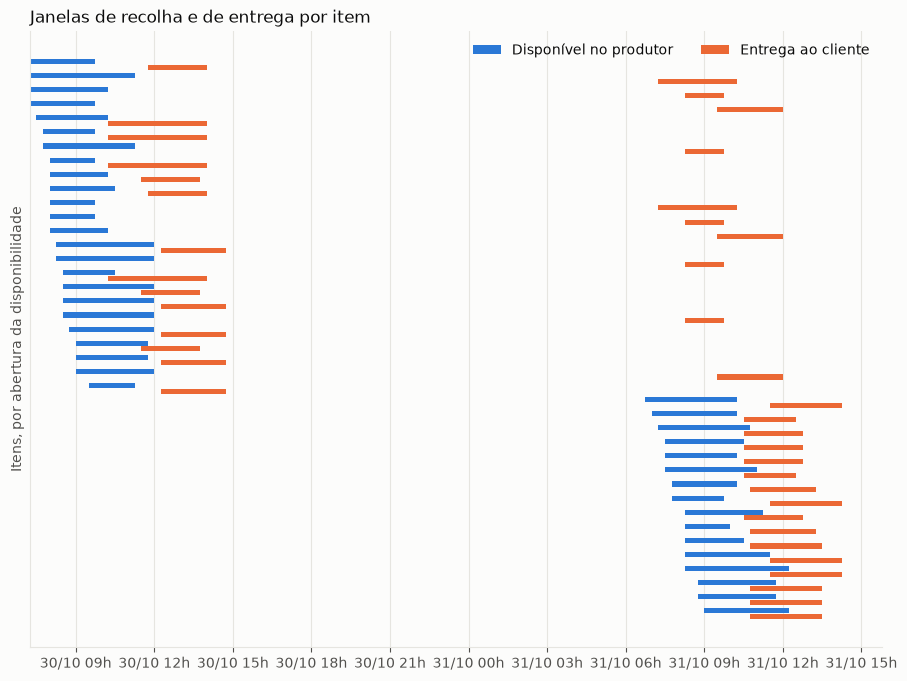

In [9]:
# Uma linha por item, ordenados pela abertura da disponibilidade
ordenados = itens.sort_values(["availability_start", "delivery_start"]).reset_index(drop=True)
y = ordenados.index

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(y - 0.2, ordenados["availability_end"] - ordenados["availability_start"], left=ordenados["availability_start"],
        height=0.36, color=AZUL, label="Disponível no produtor")
ax.barh(y + 0.2, ordenados["delivery_end"] - ordenados["delivery_start"], left=ordenados["delivery_start"],
        height=0.36, color=LARANJA, label="Entrega ao cliente")
# Duas faixas por item, porque em alguns a entrega abre antes de a disponibilidade fechar
ax.set_yticks([])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_ylabel("Itens, por abertura da disponibilidade")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m %Hh"))
ax.set_title("Janelas de recolha e de entrega por item")
ax.legend(frameon=False, loc="upper right", ncols=2)
plt.show()

## 4. Pesos vs. capacidades

In [10]:
def resumo_cargas(t):
    """Peso total a transportar face à capacidade da frota numa só viagem."""
    it = tabela_itens(t)
    v = t["vehicles"]["capacity_kg"]
    return pd.Series({
        "peso total (kg)": round(it["weight_kg"].sum(), 1),
        "capacidade da frota por viagem (kg)": v.sum(),
        "viagens mínimas de recolha (frota completa)": int(np.ceil(it["weight_kg"].sum() / v.sum())),
        "maior encomenda (kg)": round(it.groupby("order_id")["weight_kg"].sum().max(), 1),
        "maior item (kg)": it["weight_kg"].max(),
        "menor capacidade de veículo (kg)": v.min(),
        "recolhas no dia 30 (kg)": round(it.loc[it["availability_start"].dt.day == 30, "weight_kg"].sum(), 1),
        "recolhas no dia 31 (kg)": round(it.loc[it["availability_start"].dt.day == 31, "weight_kg"].sum(), 1),
        "entregas no dia 30 (kg)": round(it.loc[it["delivery_start"].dt.day == 30, "weight_kg"].sum(), 1),
        "entregas no dia 31 (kg)": round(it.loc[it["delivery_start"].dt.day == 31, "weight_kg"].sum(), 1),
    })


resumo_cargas(tiny).to_frame("valor")

,valor
peso total (kg),270.0
capacidade da frota por viagem (kg),350.0
viagens mínimas de recolha (frota completa),1.0
maior encomenda (kg),51.1
maior item (kg),20.3
menor capacidade de veículo (kg),150.0
recolhas no dia 30 (kg),166.9
recolhas no dia 31 (kg),103.1
entregas no dia 30 (kg),104.6
entregas no dia 31 (kg),165.4


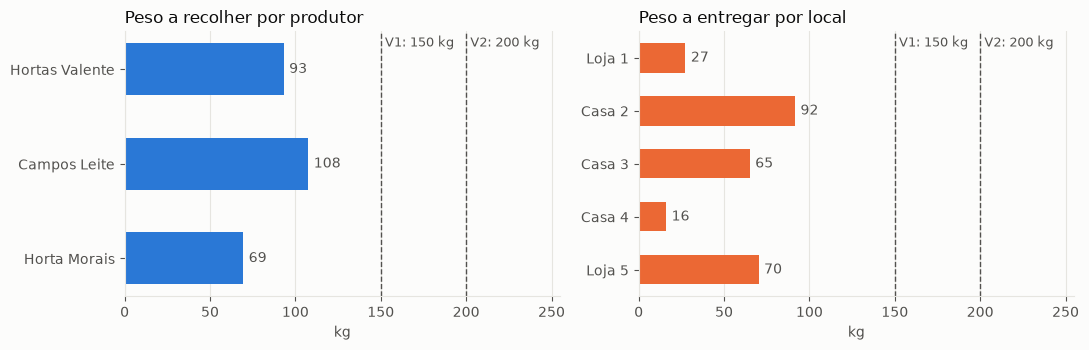

In [11]:
# Peso por paragem, comparado com a capacidade de cada veículo (linhas de referência)
por_produtor = itens.groupby("producer_id")["weight_kg"].sum().rename(tiny["producers"].set_index("producer_id")["name"])
por_entrega = itens.groupby("delivery_location_id")["weight_kg"].sum().rename(tiny["delivery_locations"].set_index("delivery_location_id")["name"])

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, serie, cor, titulo in [(eixos[0], por_produtor, AZUL, "Peso a recolher por produtor"),
                               (eixos[1], por_entrega, LARANJA, "Peso a entregar por local")]:
    ax.barh(serie.index, serie.values, height=0.55, color=cor)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("kg")
    ax.set_xlim(0, 255)
    ax.set_title(titulo)
    for i, valor in enumerate(serie.values):
        ax.annotate(f"{valor:.0f}", (valor, i), xytext=(4, 0), textcoords="offset points", va="center", color=TINTA_2)
    for _, veiculo in tiny["vehicles"].iterrows():
        ax.axvline(veiculo["capacity_kg"], color=TINTA_2, lw=1, ls="--")
        ax.annotate(f"V{veiculo['vehicle_id']}: {veiculo['capacity_kg']:.0f} kg",
                    (veiculo["capacity_kg"], 1), xycoords=("data", "axes fraction"),
                    xytext=(3, -3), textcoords="offset points", ha="left", va="top", color=TINTA_2, fontsize=9)
fig.tight_layout()
plt.show()

## 5. Mapa das paragens

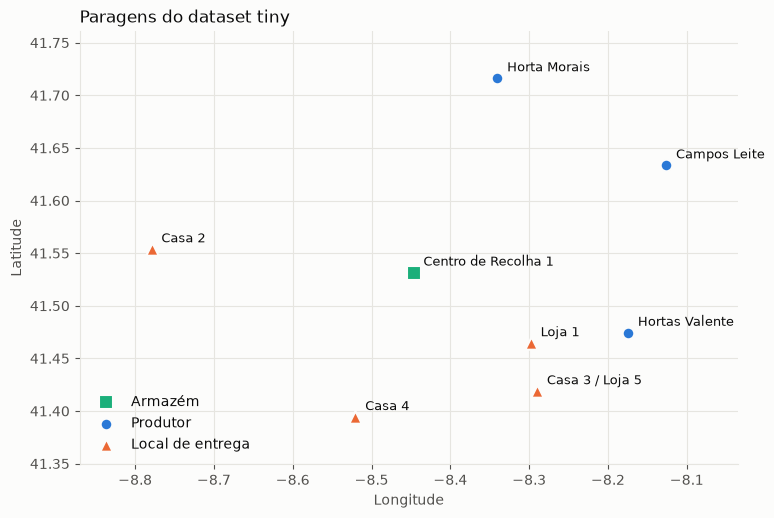

In [12]:
loc = tiny["locations"]
TIPOS = [("collection_center", "Armazém", AQUA, "s", 110),
         ("producer", "Produtor", AZUL, "o", 70),
         ("delivery_location", "Local de entrega", LARANJA, "^", 80)]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for tipo, rotulo, cor, marcador, tamanho in TIPOS:
    g = loc[loc["location_type"] == tipo]
    ax.scatter(g["longitude"], g["latitude"], s=tamanho, c=cor, marker=marcador, label=rotulo,
               edgecolors="#fcfcfb", linewidths=1.5, zorder=3)

# Paragens com as mesmas coordenadas partilham um só rótulo
for (lat, lon), g in loc.groupby(["latitude", "longitude"]):
    ax.annotate(" / ".join(g["name"]), (lon, lat), xytext=(7, 5), textcoords="offset points", fontsize=9)

# Corrige a proporção: um grau de longitude é mais curto do que um de latitude
ax.set_aspect(1 / np.cos(np.radians(loc["latitude"].mean())))
ax.margins(0.14)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Paragens do dataset tiny")
ax.legend(frameon=False, loc="lower left")
plt.show()

## 6. Comparação com o dataset small

As mesmas validações, para sabermos o que muda ao passar para a instância maior.

In [13]:
small = carregar(PASTA_SMALL)
comparacao = lambda f: pd.DataFrame({"tiny": f(tiny), "small": f(small)})
pd.concat([comparacao(f) for f in (validar_integridade, validar_matriz, validar_janelas, resumo_cargas)])

,tiny,small
valores em falta,0.000,0.000
chaves primárias repetidas,0.000,0.000
chaves estrangeiras órfãs,0.000,0.000
encomendas sem itens,0.000,0.000
encomendas não confirmadas,0.000,0.000
quantidades <= 0,0.000,0.000
peso != quantidade x peso unitário,0.000,0.000
clientes com mais de uma encomenda,0.000,4.000
pares em falta,0.000,0.000
pares assimétricos,0.000,0.000


In [14]:
# Colocalizações no small: inclui um produtor no mesmo sítio do armazém
loc = small["locations"]
loc[loc.duplicated(["latitude", "longitude"], keep=False)].sort_values(["latitude", "longitude"])

,location_id,location_type,ref_id,name,municipality,latitude,longitude
3,4,producer,4,Courela Carvalho,Braga,41.531493,-8.446483
6,7,collection_center,1,Centro de Recolha 1,Braga,41.531493,-8.446483
7,8,delivery_location,1,Casa 1,Amares,41.610626,-8.367063
12,13,delivery_location,6,Loja 6,Amares,41.610626,-8.367063


## 7. Conclusões da EDA

**Integridade.** Os dois datasets estão limpos: sem valores em falta, chaves órfãs nem pesos incoerentes. A matriz de distâncias está completa, é simétrica, respeita a desigualdade triangular e coincide com a fórmula do enunciado (a menos de arredondamentos).

**Janelas temporais.** Nenhum item é inviável por si só: em rota dedicada, a folga mínima é de 157.8 min no tiny e 110.6 min no small. Isto é uma condição necessária, não prova que exista uma solução conjunta para todos os itens com 2 veículos; isso cabe à procura e ao CSP.

**Armazém.** Nenhum item é obrigado a ficar mais de 24 h em armazém, mas alguns podem exceder esse limite se forem recolhidos cedo e entregues tarde (8 no tiny, 15 no small). O limite tem de entrar no verificador de viabilidade.

**Capacidade.** Nenhum item ou encomenda excede o menor veículo, por isso nenhum precisa de ser dividido por capacidade. No tiny, as recolhas do dia 30 (166.9 kg) excedem o veículo 1 (150 kg); no small, o peso total (580 kg) excede a capacidade conjunta (550 kg), o que obriga a mais do que uma viagem.

**Implicações para `model.py`:**

- Um veículo pode ter de fazer várias viagens, e a rota tem de permitir várias passagens pelo armazém.
- Os pares com distância 0 são válidos (locais de entrega colocalizados e, no small, o produtor 4 no armazém). Não podem ser tratados como erro nem como "mesma paragem" sem contar o tempo de serviço.
- A precedência recolha -> armazém -> entrega tem de ser verificada para cada item, pois em alguns itens a entrega abre antes de a disponibilidade fechar.

**Questões em aberto para confirmar com o docente:**

- O veículo 1 é refrigerado, mas os produtos não indicam se precisam de frio. Assumimos, por agora, que qualquer veículo transporta qualquer produto.
- O enunciado fala em uma encomenda por cliente, mas no small há 4 encomendas de clientes repetidos. Tratamos cada encomenda de forma independente.
